# Sesion 04: Complejos simpliciales y forma de una base de datos

## Contexto
En Analisis Topologico de Datos (TDA), una nube de puntos se interpreta como una muestra discreta de un objeto geometrico subyacente. Los complejos simpliciales permiten pasar de puntos aislados a una representacion combinatoria de la forma de la base de datos.

## Objetivos de aprendizaje
1. Construir complejos Vietoris-Rips, Alpha y Cech a partir de una nube de puntos.
2. Interpretar como cambian estos complejos al modificar `max_dimension`, `max_edge_length`, `max_alpha_square` y el radio de Cech.
3. Visualizar simplices, huecos y rellenos para conectar la algebra con la geometria.
4. Usar `gudhi` y `giotto-tda` como herramientas base para TDA en Python.

## Ruta del notebook
1. Construccion de nubes de puntos sinteticas.
2. Funciones auxiliares para visualizar complejos.
3. Complejo Vietoris-Rips con `gudhi`.
4. Complejo Alpha con `gudhi`.
5. Complejo Cech y persistencia con `giotto-tda`.
6. Actividades guiadas para el estudiante.

## Preparacion

Este notebook asume una nube de puntos en dimension 2 para poder visualizar vertices, aristas y triangulos. Si alguna libreria no esta instalada, usa la siguiente celda.

Sugerencia didactica: primero ejecuta el notebook con la nube `circulos`, despues cambia a `lunas` o `blobs` y compara que huecos aparecen o desaparecen.

In [1]:
# Ejecuta esta celda solo si necesitas instalar dependencias.
# %pip install -q gudhi giotto-tda scikit-learn matplotlib plotly

In [10]:
import math
from itertools import combinations

import gudhi
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle, Polygon
from sklearn.datasets import make_blobs, make_circles, make_moons

try:
    from gtda.homology import EuclideanCechPersistence, VietorisRipsPersistence
    GIOTTO_AVAILABLE = True
    GIOTTO_IMPORT_ERROR = None
except Exception as exc:
    EuclideanCechPersistence = None
    VietorisRipsPersistence = None
    GIOTTO_AVAILABLE = False
    GIOTTO_IMPORT_ERROR = exc
    print('giotto-tda no esta disponible en este entorno; se usara gudhi como respaldo para la parte de persistencia:', exc)

np.random.seed(7)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (6, 6)

giotto-tda no esta disponible en este entorno; se usara gudhi como respaldo para la parte de persistencia: No module named 'gtda'


## 1) Nubes de puntos de referencia

Vamos a trabajar con tres colecciones sinteticas. La idea es que el estudiante observe que un mismo metodo puede comportarse de manera distinta segun la geometria de los datos.

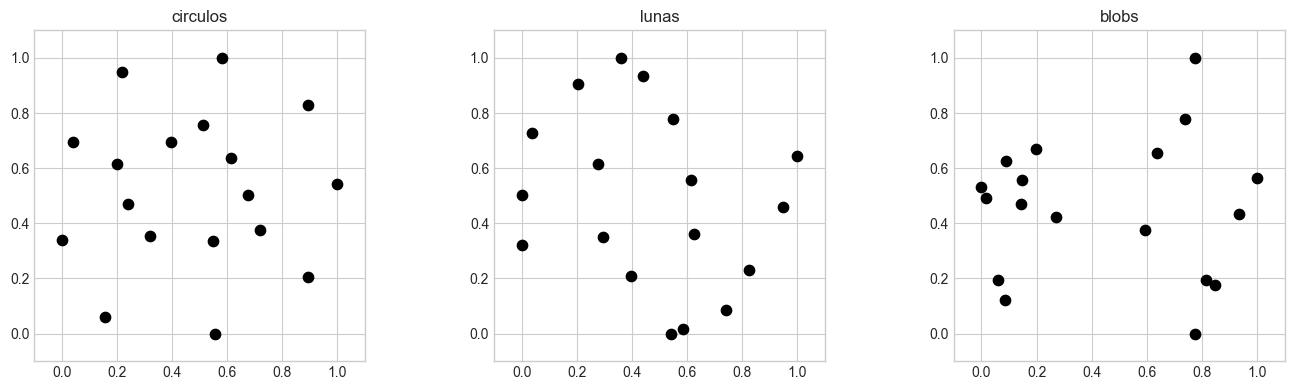

In [3]:
def normalize_points(points):
    points = np.asarray(points, dtype=float)
    min_vals = points.min(axis=0)
    max_vals = points.max(axis=0)
    scale = np.where(max_vals > min_vals, max_vals - min_vals, 1.0)
    return (points - min_vals) / scale

circle_points, _ = make_circles(n_samples=18, factor=0.45, noise=0.05, random_state=7)
moon_points, _ = make_moons(n_samples=18, noise=0.07, random_state=7)
blob_points, _ = make_blobs(
    n_samples=18,
    centers=[(-1.0, 0.0), (1.0, 0.0)],
    cluster_std=0.30,
    random_state=7,
)

datasets = {
    'circulos': normalize_points(circle_points),
    'lunas': normalize_points(moon_points),
    'blobs': normalize_points(blob_points),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pts) in zip(axes, datasets.items()):
    ax.scatter(pts[:, 0], pts[:, 1], s=55, color='black')
    ax.set_title(name)
    ax.set_aspect('equal')
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
plt.tight_layout()
plt.show()

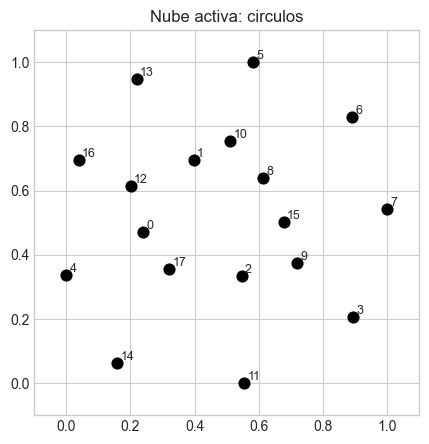

In [4]:
dataset_name = 'circulos'
points = datasets[dataset_name]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(points[:, 0], points[:, 1], s=60, color='black')
for idx, (x_coord, y_coord) in enumerate(points):
    ax.text(x_coord + 0.01, y_coord + 0.01, str(idx), fontsize=9)
ax.set_title(f'Nube activa: {dataset_name}')
ax.set_aspect('equal')
ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.1, 1.1)
plt.show()

## 2) Funciones auxiliares

Las siguientes funciones encapsulan la construccion de complejos y la visualizacion en dimension 2. Para Cech construiremos el complejo hasta dimension 2, suficiente para ver vertices, aristas, triangulos y el posible relleno de un hueco.

In [5]:
def complex_profile(simplex_tree):
    counts = {}
    max_filtration = {}
    for simplex, filtration in simplex_tree.get_filtration():
        dim = len(simplex) - 1
        counts[dim] = counts.get(dim, 0) + 1
        max_filtration[dim] = max(max_filtration.get(dim, 0.0), float(filtration))
    return {
        'dimension': simplex_tree.dimension(),
        'num_simplices': simplex_tree.num_simplices(),
        'counts_by_dim': counts,
        'max_filtration_by_dim': {dim: round(value, 4) for dim, value in max_filtration.items()},
    }


def print_complex_profile(name, simplex_tree):
    profile = complex_profile(simplex_tree)
    print(f'{name}:')
    for key, value in profile.items():
        print(f'  {key}: {value}')


def triangle_cover_radius(point_a, point_b, point_c):
    side_a = np.linalg.norm(point_b - point_c)
    side_b = np.linalg.norm(point_a - point_c)
    side_c = np.linalg.norm(point_a - point_b)
    sides = sorted([side_a, side_b, side_c])
    longest = sides[-1]

    if longest ** 2 >= sides[0] ** 2 + sides[1] ** 2:
        return longest / 2.0

    area = abs(np.linalg.det(np.vstack([point_b - point_a, point_c - point_a]))) / 2.0
    if area < 1e-12:
        return longest / 2.0

    return (side_a * side_b * side_c) / (4.0 * area)


def build_rips_complex(points, max_dimension=2, max_edge_length=0.25):
    return gudhi.RipsComplex(points=points, max_edge_length=max_edge_length).create_simplex_tree(
        max_dimension=max_dimension
    )


def build_alpha_complex(points, max_dimension=2, max_alpha_square=0.02):
    full_tree = gudhi.AlphaComplex(points=points).create_simplex_tree()
    simplex_tree = gudhi.SimplexTree()

    for simplex, filtration in full_tree.get_filtration():
        if len(simplex) - 1 <= max_dimension and filtration <= max_alpha_square:
            simplex_tree.insert(simplex, filtration=filtration)

    simplex_tree.make_filtration_non_decreasing()
    return simplex_tree


def build_cech_complex(points, max_dimension=2, radius=0.15):
    simplex_tree = gudhi.SimplexTree()
    n_points = len(points)

    for vertex in range(n_points):
        simplex_tree.insert([vertex], filtration=0.0)

    for i, j in combinations(range(n_points), 2):
        edge_radius = np.linalg.norm(points[i] - points[j]) / 2.0
        if edge_radius <= radius:
            simplex_tree.insert([i, j], filtration=edge_radius)

    if max_dimension >= 2:
        for i, j, k in combinations(range(n_points), 3):
            tri_radius = triangle_cover_radius(points[i], points[j], points[k])
            if tri_radius <= radius:
                simplex_tree.insert([i, j, k], filtration=tri_radius)

    simplex_tree.make_filtration_non_decreasing()
    return simplex_tree


def plot_simplex_tree(points, simplex_tree, ax=None, title='', balls_radius=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))

    points = np.asarray(points)

    if balls_radius is not None:
        for point in points:
            circle = Circle((point[0], point[1]), balls_radius, fill=False, linestyle='--', linewidth=1.0, alpha=0.35)
            ax.add_patch(circle)

    triangles = []
    edges = []
    for simplex, _ in simplex_tree.get_filtration():
        dim = len(simplex) - 1
        if dim == 2:
            triangles.append(tuple(simplex))
        elif dim == 1:
            edges.append(tuple(simplex))

    for triangle in triangles:
        polygon = Polygon(points[list(triangle)], closed=True, facecolor='tab:orange', edgecolor='none', alpha=0.25)
        ax.add_patch(polygon)

    for i, j in edges:
        ax.plot(points[[i, j], 0], points[[i, j], 1], color='tab:red', linewidth=1.8, alpha=0.85)

    ax.scatter(points[:, 0], points[:, 1], color='black', s=55, zorder=3)
    for idx, (x_coord, y_coord) in enumerate(points):
        ax.text(x_coord + 0.01, y_coord + 0.01, str(idx), fontsize=9)

    ax.set_title(title)
    ax.set_aspect('equal')
    ax.set_xlim(points[:, 0].min() - 0.1, points[:, 0].max() + 0.1)
    ax.set_ylim(points[:, 1].min() - 0.1, points[:, 1].max() + 0.1)
    return ax

## 3) Vietoris-Rips con `gudhi`

El complejo Vietoris-Rips agrega una arista entre dos puntos si su distancia es menor o igual a `max_edge_length`. Despues agrega automaticamente todos los simplices cuyos pares de vertices ya estaban conectados. Por eso, cuando `max_dimension = 2`, los triangulos aparecen como rellenos del grafo.

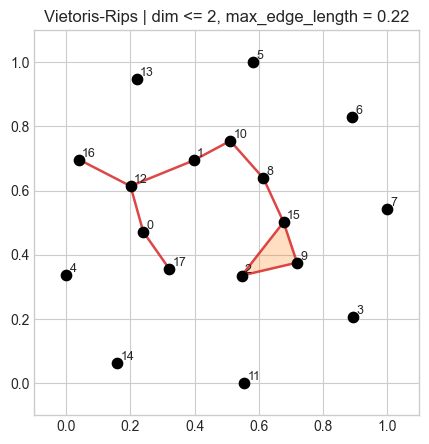

Rips:
  dimension: 2
  num_simplices: 29
  counts_by_dim: {0: 18, 1: 10, 2: 1}
  max_filtration_by_dim: {0: 0.0, 1: 0.2126, 2: 0.2115}


In [6]:
rips_max_dimension = 2
rips_max_edge_length = 0.22

rips_tree = build_rips_complex(
    points,
    max_dimension=rips_max_dimension,
    max_edge_length=rips_max_edge_length,
)

fig, ax = plt.subplots(figsize=(5, 5))
plot_simplex_tree(
    points,
    rips_tree,
    ax=ax,
    title=f'Vietoris-Rips | dim <= {rips_max_dimension}, max_edge_length = {rips_max_edge_length}',
)
plt.show()

print_complex_profile('Rips', rips_tree)

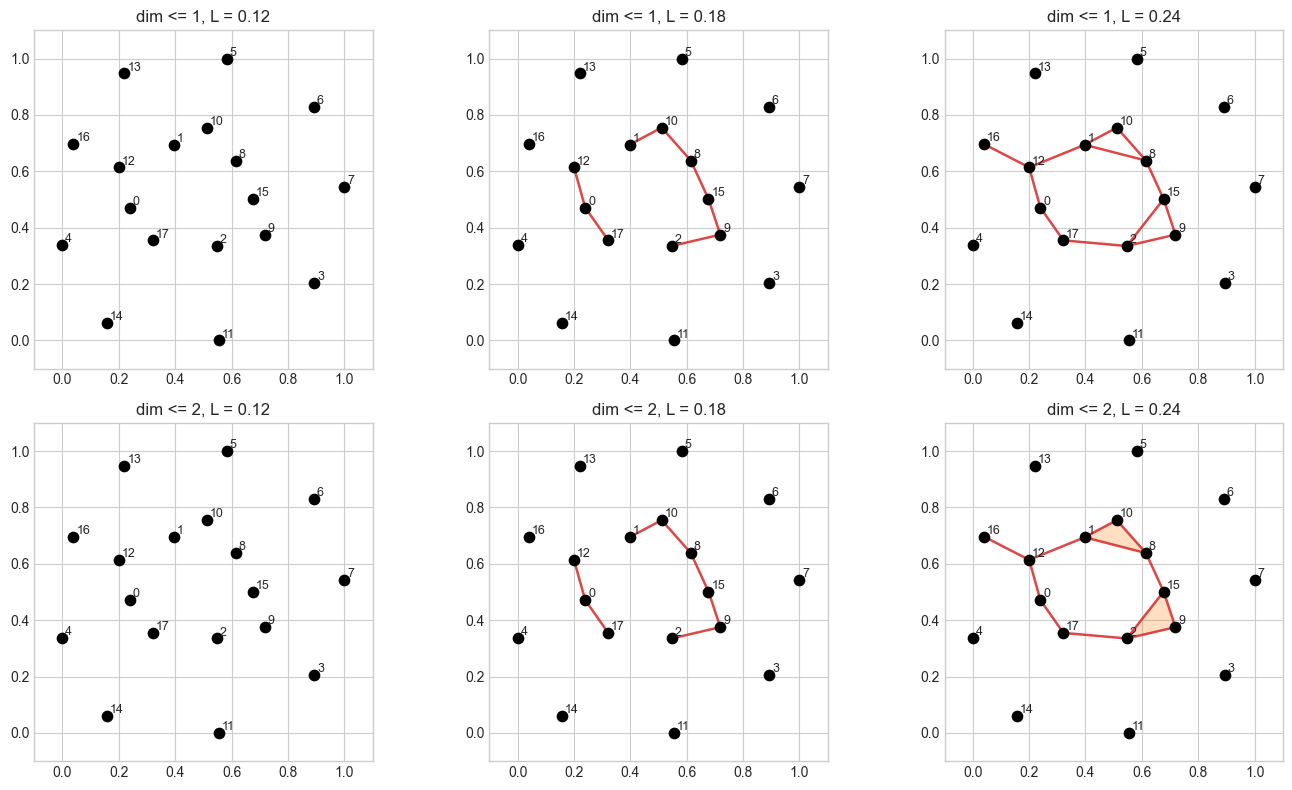

Observa:
- Al aumentar max_edge_length aparecen mas aristas y triangulos.
- Al aumentar max_dimension, el complejo deja de ser solo grafo y puede rellenar huecos.


In [7]:
rips_lengths = [0.12, 0.18, 0.24]
rips_dims = [1, 2]

fig, axes = plt.subplots(len(rips_dims), len(rips_lengths), figsize=(14, 8))
for row, max_dimension in enumerate(rips_dims):
    for col, max_edge_length in enumerate(rips_lengths):
        tree = build_rips_complex(points, max_dimension=max_dimension, max_edge_length=max_edge_length)
        plot_simplex_tree(
            points,
            tree,
            ax=axes[row, col],
            title=f'dim <= {max_dimension}, L = {max_edge_length}',
        )

plt.tight_layout()
plt.show()

print('Observa:')
print('- Al aumentar max_edge_length aparecen mas aristas y triangulos.')
print('- Al aumentar max_dimension, el complejo deja de ser solo grafo y puede rellenar huecos.')

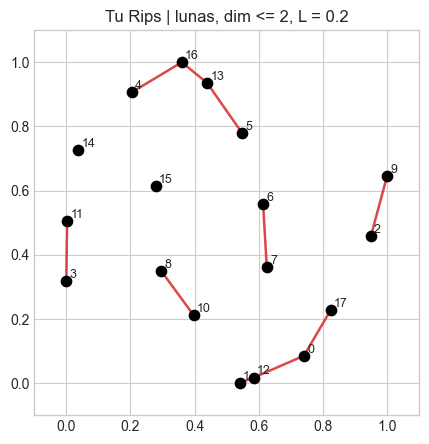

Tu Rips:
  dimension: 1
  num_simplices: 28
  counts_by_dim: {0: 18, 1: 10}
  max_filtration_by_dim: {0: 0.0, 1: 0.1971}


In [11]:
# ACTIVIDAD 1
# Cambia el dataset y los parametros para producir una nueva aproximacion.
student_dataset = 'lunas'
student_max_dimension = 2
student_max_edge_length = 0.20

student_points = datasets[student_dataset]
student_rips = build_rips_complex(
    student_points,
    max_dimension=student_max_dimension,
    max_edge_length=student_max_edge_length,
)

fig, ax = plt.subplots(figsize=(5, 5))
plot_simplex_tree(
    student_points,
    student_rips,
    ax=ax,
    title=f'Tu Rips | {student_dataset}, dim <= {student_max_dimension}, L = {student_max_edge_length}',
)
plt.show()

print_complex_profile('Tu Rips', student_rips)

# Escribe aqui tu conclusion:
# 1. Que parte de la forma de la nube se conserva?
# 2. Que parte se sobreconecta o se pierde?

## 4) Alpha complex con `gudhi`

El complejo Alpha utiliza geometria euclidiana y una triangulacion de Delaunay para generar una representacion normalmente mas economica que Vietoris-Rips. En `gudhi`, su filtracion se reporta en terminos relacionados con radios al cuadrado, por eso aqui usamos el parametro `max_alpha_square`.

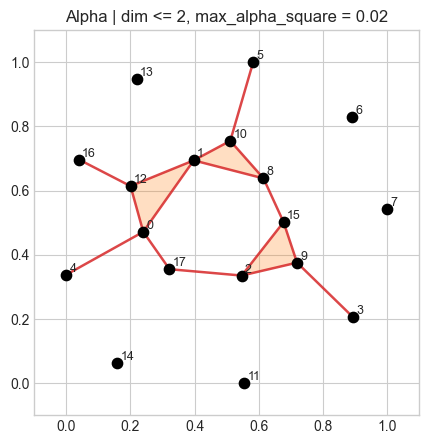

Alpha:
  dimension: 2
  num_simplices: 37
  counts_by_dim: {0: 18, 1: 16, 2: 3}
  max_filtration_by_dim: {0: 0.0, 1: 0.0188, 2: 0.0188}
Nota: compara con Rips, pero recuerda que las escalas no son identicas.


In [8]:
alpha_max_dimension = 2
alpha_max_alpha_square = 0.02

alpha_tree = build_alpha_complex(
    points,
    max_dimension=alpha_max_dimension,
    max_alpha_square=alpha_max_alpha_square,
)

fig, ax = plt.subplots(figsize=(5, 5))
plot_simplex_tree(
    points,
    alpha_tree,
    ax=ax,
    title=f'Alpha | dim <= {alpha_max_dimension}, max_alpha_square = {alpha_max_alpha_square}',
)
plt.show()

print_complex_profile('Alpha', alpha_tree)
print('Nota: compara con Rips, pero recuerda que las escalas no son identicas.')

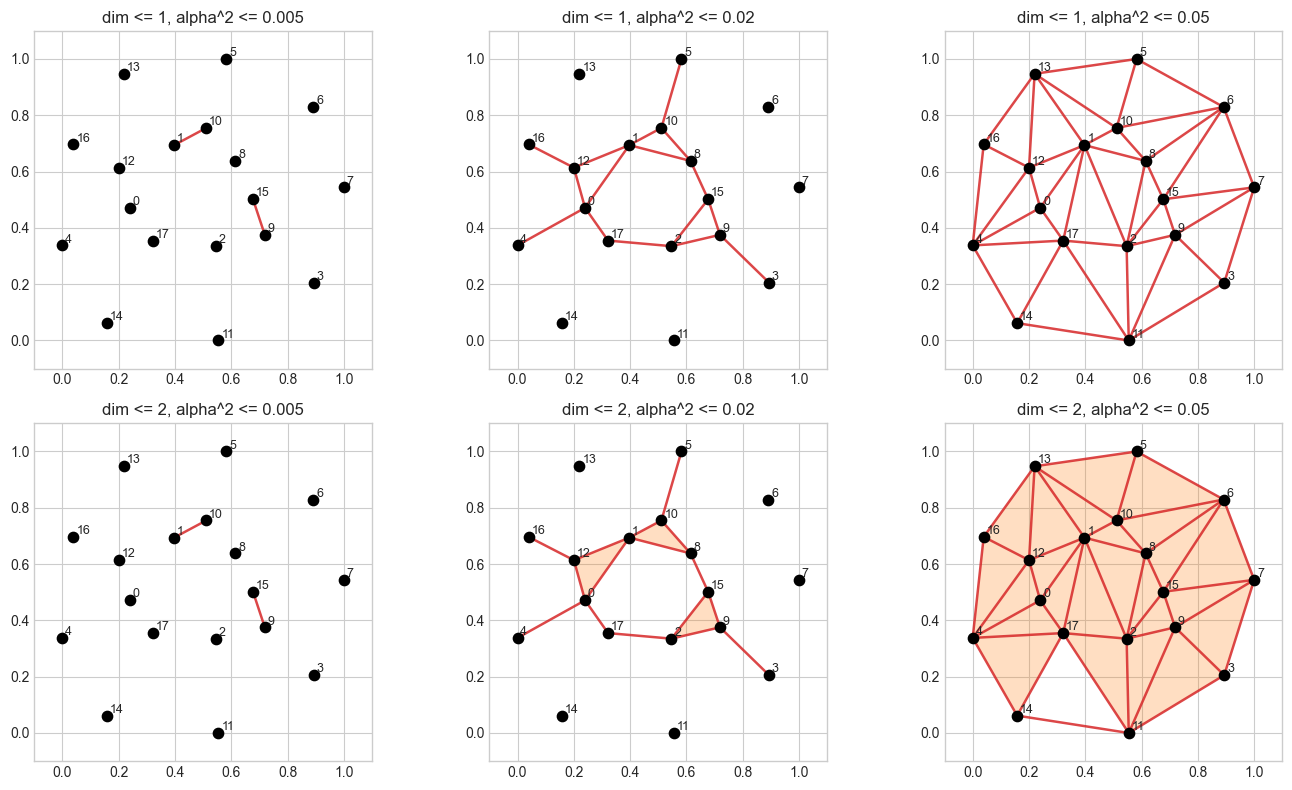

Pregunta guiada:
En que casos Alpha parece capturar mejor la geometria local que Rips?


In [12]:
alpha_thresholds = [0.005, 0.02, 0.05]
alpha_dims = [1, 2]

fig, axes = plt.subplots(len(alpha_dims), len(alpha_thresholds), figsize=(14, 8))
for row, max_dimension in enumerate(alpha_dims):
    for col, threshold in enumerate(alpha_thresholds):
        tree = build_alpha_complex(points, max_dimension=max_dimension, max_alpha_square=threshold)
        plot_simplex_tree(
            points,
            tree,
            ax=axes[row, col],
            title=f'dim <= {max_dimension}, alpha^2 <= {threshold}',
        )

plt.tight_layout()
plt.show()

print('Pregunta guiada:')
print('En que casos Alpha parece capturar mejor la geometria local que Rips?')

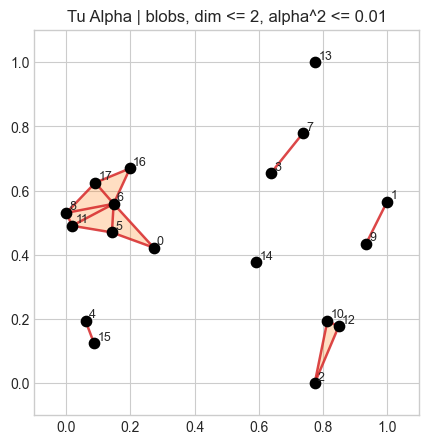

Tu Alpha:
  dimension: 2
  num_simplices: 41
  counts_by_dim: {0: 18, 1: 17, 2: 6}
  max_filtration_by_dim: {0: 0.0, 1: 0.0098, 2: 0.0098}


In [13]:
# ACTIVIDAD 2
# Repite el experimento Alpha con otra nube y otra escala.
student_alpha_dataset = 'blobs'
student_alpha_dim = 2
student_alpha_square = 0.01

student_points = datasets[student_alpha_dataset]
student_alpha = build_alpha_complex(
    student_points,
    max_dimension=student_alpha_dim,
    max_alpha_square=student_alpha_square,
)

fig, ax = plt.subplots(figsize=(5, 5))
plot_simplex_tree(
    student_points,
    student_alpha,
    ax=ax,
    title=f'Tu Alpha | {student_alpha_dataset}, dim <= {student_alpha_dim}, alpha^2 <= {student_alpha_square}',
)
plt.show()

print_complex_profile('Tu Alpha', student_alpha)

# Escribe aqui tu conclusion:
# 1. Que diferencia ves contra Rips en la misma nube?
# 2. Donde aparecen rellenos demasiado pronto o demasiado tarde?

## 5) Cech: bolas, intersecciones y persistencia

En el complejo Cech, un simplex aparece cuando las bolas cerradas centradas en sus vertices tienen interseccion comun. En 2D, esto puede visualizarse dibujando bolas de radio `r`. Aqui construiremos el complejo hasta dimension 2 para visualizar la idea y usaremos `giotto-tda` para conectar con el diagrama de persistencia.

Si `giotto-tda` no esta disponible en el entorno, la celda correspondiente usara `gudhi` como respaldo para que el notebook siga siendo ejecutable.

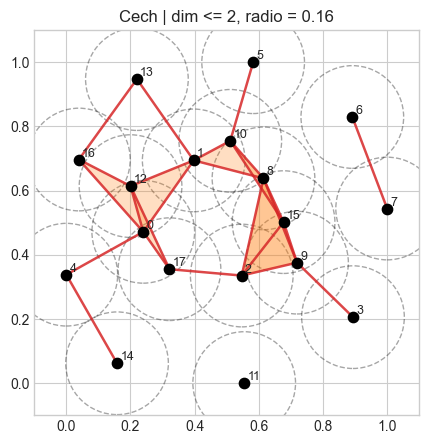

Cech:
  dimension: 2
  num_simplices: 52
  counts_by_dim: {0: 18, 1: 25, 2: 9}
  max_filtration_by_dim: {0: 0.0, 1: 0.1591, 2: 0.1569}
Interpretacion: una arista aparece cuando dos bolas se tocan; un triangulo aparece cuando tres bolas tienen interseccion comun.


In [9]:
cech_radius = 0.16
cech_max_dimension = 2

cech_tree = build_cech_complex(points, max_dimension=cech_max_dimension, radius=cech_radius)

fig, ax = plt.subplots(figsize=(5, 5))
plot_simplex_tree(
    points,
    cech_tree,
    ax=ax,
    title=f'Cech | dim <= {cech_max_dimension}, radio = {cech_radius}',
    balls_radius=cech_radius,
)
plt.show()

print_complex_profile('Cech', cech_tree)
print('Interpretacion: una arista aparece cuando dos bolas se tocan; un triangulo aparece cuando tres bolas tienen interseccion comun.')

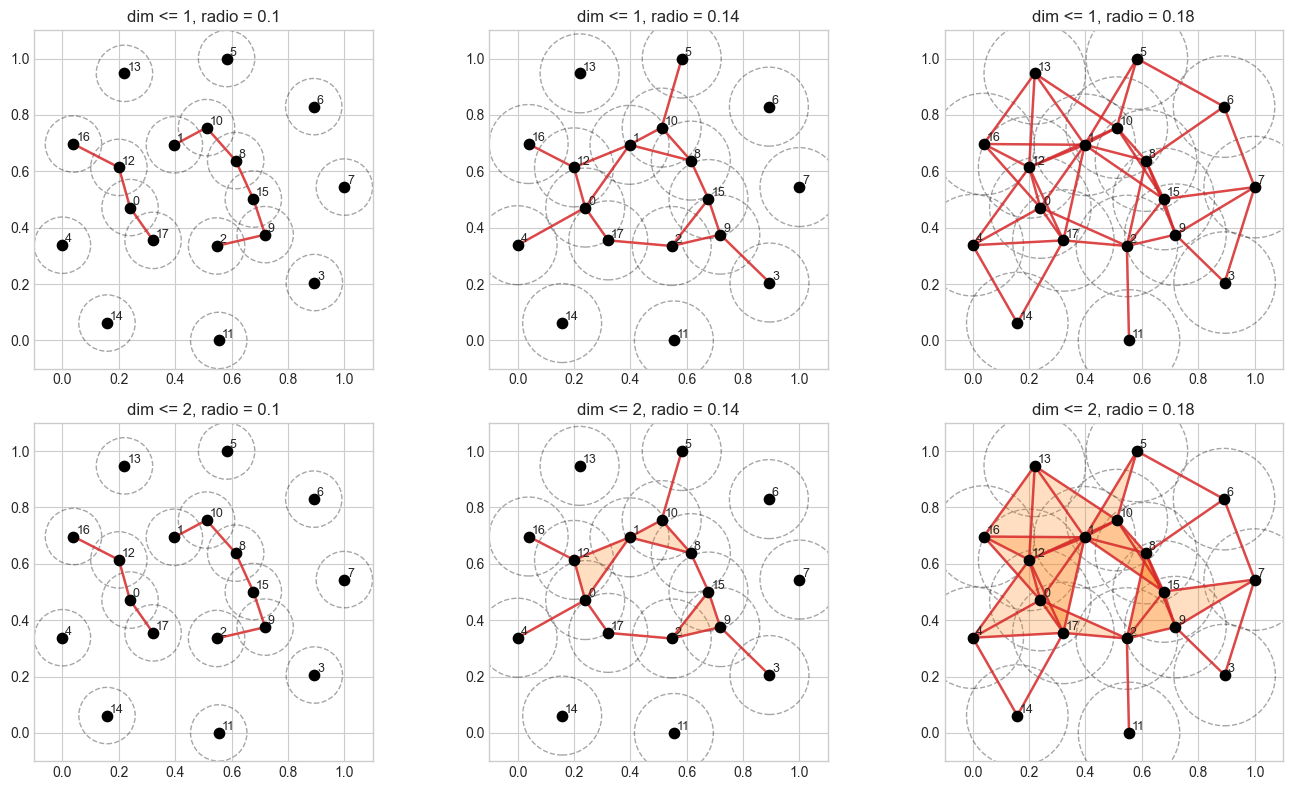

Observa como el radio controla la conectividad y el relleno del hueco central.


In [14]:
cech_radii = [0.10, 0.14, 0.18]
cech_dims = [1, 2]

fig, axes = plt.subplots(len(cech_dims), len(cech_radii), figsize=(14, 8))
for row, max_dimension in enumerate(cech_dims):
    for col, radius in enumerate(cech_radii):
        tree = build_cech_complex(points, max_dimension=max_dimension, radius=radius)
        plot_simplex_tree(
            points,
            tree,
            ax=axes[row, col],
            title=f'dim <= {max_dimension}, radio = {radius}',
            balls_radius=radius,
        )

plt.tight_layout()
plt.show()

print('Observa como el radio controla la conectividad y el relleno del hueco central.')

giotto-tda no pudo instalarse en este .venv; se muestra un respaldo con gudhi.
Motivo de importacion: No module named 'gtda'


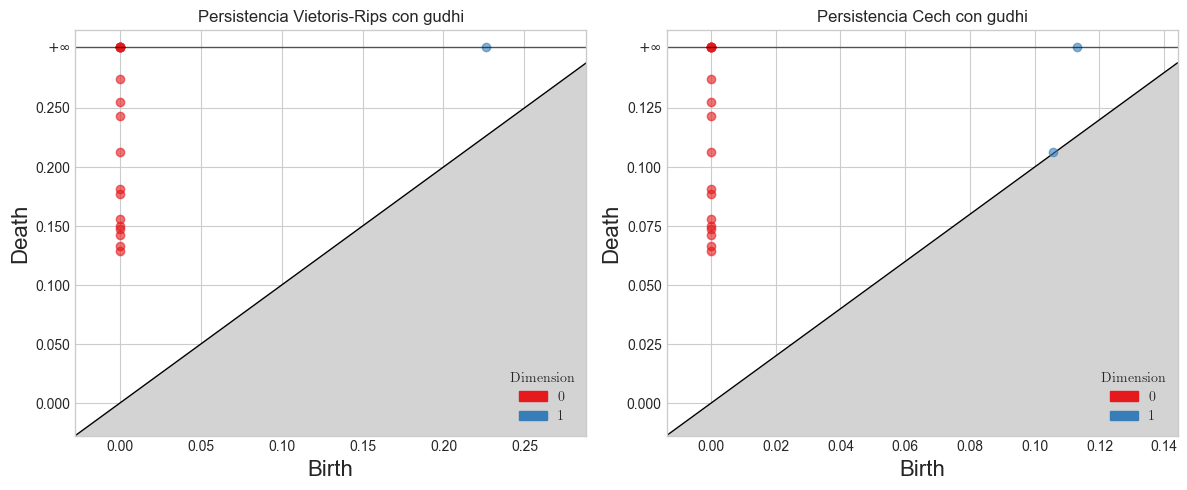

Compara la presencia y duracion del ciclo principal en H1 entre ambas filtraciones.


In [15]:
if GIOTTO_AVAILABLE:
    point_cloud = points[None, :, :]

    vr_persistence = VietorisRipsPersistence(homology_dimensions=(0, 1), max_edge_length=0.30)
    cech_persistence = EuclideanCechPersistence(homology_dimensions=(0, 1), max_edge_length=0.30)

    vr_diagram = vr_persistence.fit_transform(point_cloud)
    cech_diagram = cech_persistence.fit_transform(point_cloud)

    fig_vr = VietorisRipsPersistence.plot(vr_diagram, sample=0)
    fig_vr.update_layout(title='Persistencia Vietoris-Rips con giotto-tda')
    fig_vr.show()

    fig_cech = EuclideanCechPersistence.plot(cech_diagram, sample=0)
    fig_cech.update_layout(title='Persistencia Cech con giotto-tda')
    fig_cech.show()

    print('Compara la vida del ciclo principal en H1 entre ambas filtraciones.')
else:
    print('giotto-tda no pudo instalarse en este .venv; se muestra un respaldo con gudhi.')
    print('Motivo de importacion:', GIOTTO_IMPORT_ERROR)

    rips_tree_persistence = build_rips_complex(points, max_dimension=2, max_edge_length=0.30)
    cech_tree_persistence = build_cech_complex(points, max_dimension=2, radius=0.15)

    rips_diagram = rips_tree_persistence.persistence()
    cech_diagram = cech_tree_persistence.persistence()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    gudhi.plot_persistence_diagram(rips_diagram, axes=axes[0], legend=True)
    axes[0].set_title('Persistencia Vietoris-Rips con gudhi')
    gudhi.plot_persistence_diagram(cech_diagram, axes=axes[1], legend=True)
    axes[1].set_title('Persistencia Cech con gudhi')
    plt.tight_layout()
    plt.show()

    print('Compara la presencia y duracion del ciclo principal en H1 entre ambas filtraciones.')

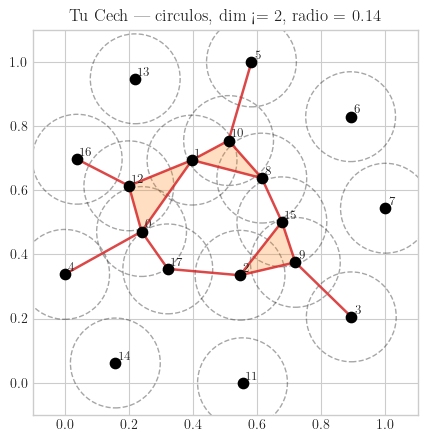

Tu Cech:
  dimension: 2
  num_simplices: 37
  counts_by_dim: {0: 18, 1: 16, 2: 3}
  max_filtration_by_dim: {0: 0.0, 1: 0.1372, 2: 0.1363}


In [16]:
# ACTIVIDAD 3
# Ajusta el radio de Cech y compara la visualizacion de bolas con el hueco detectado.
student_cech_dataset = 'circulos'
student_cech_dim = 2
student_cech_radius = 0.14

student_points = datasets[student_cech_dataset]
student_cech = build_cech_complex(
    student_points,
    max_dimension=student_cech_dim,
    radius=student_cech_radius,
)

fig, ax = plt.subplots(figsize=(5, 5))
plot_simplex_tree(
    student_points,
    student_cech,
    ax=ax,
    title=f'Tu Cech | {student_cech_dataset}, dim <= {student_cech_dim}, radio = {student_cech_radius}',
    balls_radius=student_cech_radius,
)
plt.show()

print_complex_profile('Tu Cech', student_cech)

# Escribe aqui tu conclusion:
# 1. En que momento el hueco central deja de ser visible?
# 2. Como se relaciona eso con el diagrama de persistencia?

## 6) Comparacion final y reto

Los tres complejos buscan aproximar la forma de los datos, pero lo hacen con criterios geometricos distintos. No existe un parametro universal: la escala y la dimension maxima deben interpretarse junto con la nube, el ruido y la pregunta de modelado.

### Reto sugerido
1. Repite todo el flujo con `dataset_name = 'lunas'`.
2. Elige un conjunto de parametros para cada complejo.
3. Decide cual complejo representa mejor la forma de la nube y justifica tu respuesta con una grafica y una observacion topologica.

In [17]:
comparison = {
    'Rips': build_rips_complex(points, max_dimension=2, max_edge_length=0.22),
    'Alpha': build_alpha_complex(points, max_dimension=2, max_alpha_square=0.02),
    'Cech': build_cech_complex(points, max_dimension=2, radius=0.16),
}

for name, simplex_tree in comparison.items():
    print_complex_profile(name, simplex_tree)
    print('-' * 40)

Rips:
  dimension: 2
  num_simplices: 29
  counts_by_dim: {0: 18, 1: 10, 2: 1}
  max_filtration_by_dim: {0: 0.0, 1: 0.2126, 2: 0.2115}
----------------------------------------
Alpha:
  dimension: 2
  num_simplices: 37
  counts_by_dim: {0: 18, 1: 16, 2: 3}
  max_filtration_by_dim: {0: 0.0, 1: 0.0188, 2: 0.0188}
----------------------------------------
Cech:
  dimension: 2
  num_simplices: 52
  counts_by_dim: {0: 18, 1: 25, 2: 9}
  max_filtration_by_dim: {0: 0.0, 1: 0.1591, 2: 0.1569}
----------------------------------------
